In [1]:
REG_NO = "008"
SEED = 8
HOG_CELL = (8, 8)
SIFT_GRID = 6

In [2]:
!pip install medmnist -q

In [3]:
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from medmnist import BloodMNIST
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# **Q1. Data setup**

In [4]:
KEEP = {1: 'eosinophil', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}
names = list(KEEP.values())
sizes = {'train': 100, 'val': 30, 'test': 30}
rng = np.random.default_rng(SEED)

def prep(imgs):
    return np.array([cv2.resize(cv2.cvtColor(i, cv2.COLOR_RGB2GRAY), (128, 128)) for i in imgs])

def load_split(split, n):
    ds = BloodMNIST(split=split, download=True, size=64)
    X, y = ds.imgs, ds.labels.ravel()
    Xs, ys = [], []
    for new_label, c in enumerate(KEEP):
        idx = rng.choice(np.where(y == c)[0], n, replace=False)
        Xs.append(X[idx])
        ys += [new_label] * n
    return prep(np.concatenate(Xs)), np.array(ys)

Xtr, ytr = load_split('train', sizes['train'])
Xva, yva = load_split('val', sizes['val'])
Xte, yte = load_split('test', sizes['test'])

for name, X, y in [('train', Xtr, ytr), ('val', Xva, yva), ('test', Xte, yte)]:
    counts = {names[k]: v for k, v in sorted(Counter(y).items())}
    print(name, X.shape, y.shape, counts)

100%|██████████| 156M/156M [00:10<00:00, 14.7MB/s]


train (400, 128, 128) (400,) {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val (120, 128, 128) (120,) {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test (120, 128, 128) (120,) {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


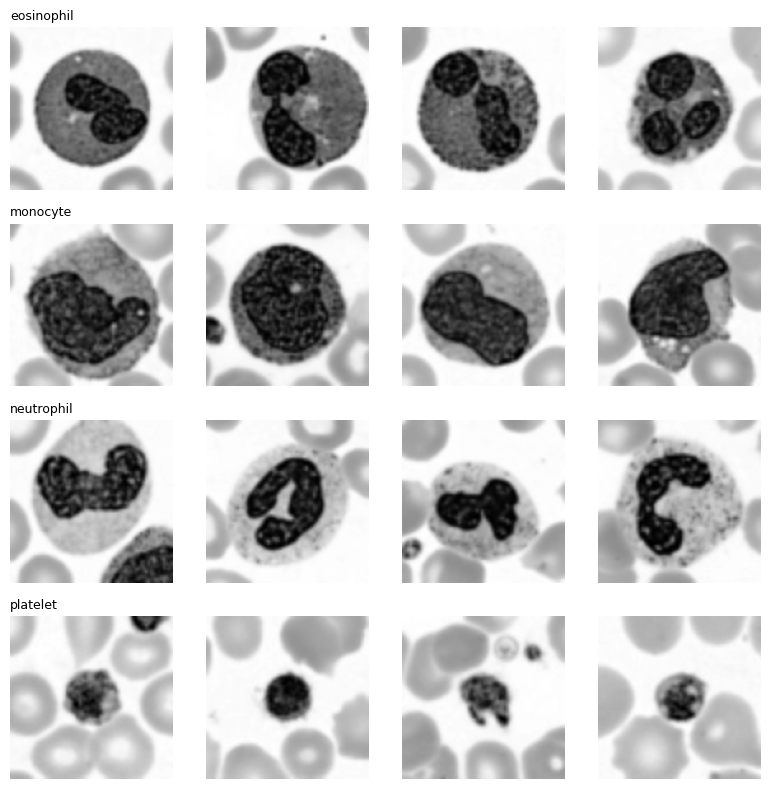

In [5]:
fig, ax = plt.subplots(4, 4, figsize=(8, 8))
for c in range(4):
    idx = np.where(ytr == c)[0][:4]
    for j, i in enumerate(idx):
        ax[c, j].imshow(Xtr[i], cmap='gray')
        ax[c, j].axis('off')
    ax[c, 0].set_title(names[c], fontsize=9, loc='left')
plt.tight_layout()
plt.show()

# **Q2. HOG + SVM**

In [6]:
def get_hog(img, vis=False):
    return hog(img, orientations=9, pixels_per_cell=HOG_CELL,
               cells_per_block=(2, 2), block_norm='L2-Hys', visualize=vis)

def hog_feats(X):
    return np.array([get_hog(i) for i in X])

Htr, Hva = hog_feats(Xtr), hog_feats(Xva)
print(Htr.shape, Hva.shape)
print("HOG feature length:", Htr.shape[1])

(400, 8100) (120, 8100)
HOG feature length: 8100


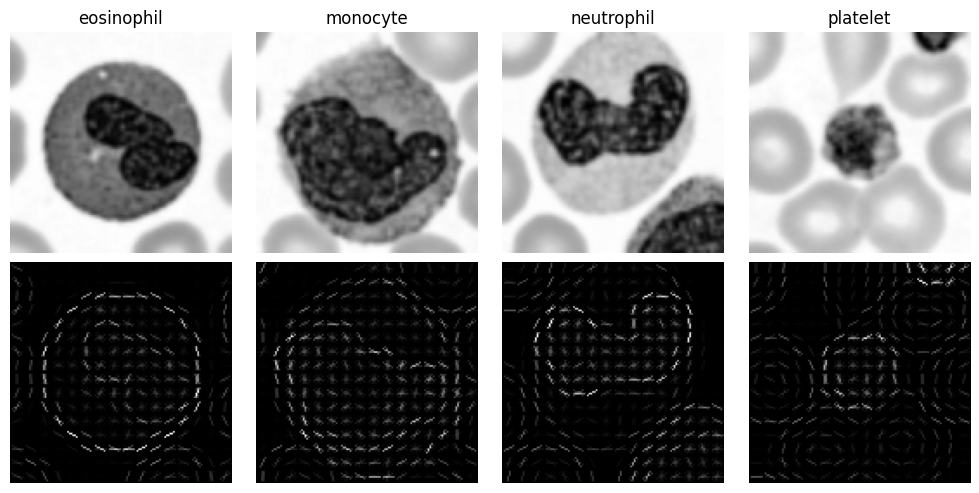

In [8]:
fig, ax = plt.subplots(2, 4, figsize=(10, 5))
for c in range(4):
    img = Xtr[np.where(ytr == c)[0][0]]
    _, hi = get_hog(img, vis=True)
    ax[0, c].imshow(img, cmap='gray'); ax[0, c].set_title(names[c]); ax[0, c].axis('off')
    ax[1, c].imshow(hi, cmap='gray'); ax[1, c].axis('off')
plt.tight_layout()
plt.show()

C=0.1  val acc=0.7417
C=1  val acc=0.7250
C=10  val acc=0.7250
Best C: 0.1
Accuracy: 0.7417
Macro-F1: 0.7399
[[18  7  4  1]
 [ 1 25  4  0]
 [ 9  3 18  0]
 [ 0  0  2 28]]


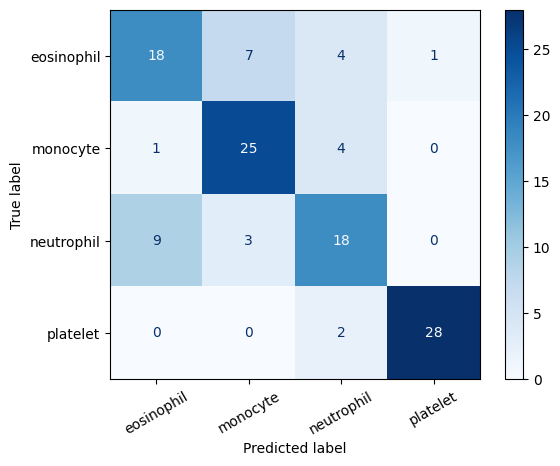

In [9]:
def fit_best(Ftr, ytr, Fva, yva):
    best = None
    for C in [0.1, 1, 10]:
        m = LinearSVC(C=C, max_iter=20000, random_state=SEED).fit(Ftr, ytr)
        acc = accuracy_score(yva, m.predict(Fva))
        print(f"C={C}  val acc={acc:.4f}")
        if best is None or acc > best[0]:
            best = (acc, C, m)
    print("Best C:", best[1])
    return best[2]

def report(model, F, y):
    p = model.predict(F)
    print("Accuracy:", round(accuracy_score(y, p), 4))
    print("Macro-F1:", round(f1_score(y, p, average='macro'), 4))
    cm = confusion_matrix(y, p)
    print(cm)
    ConfusionMatrixDisplay(cm, display_labels=names).plot(cmap='Blues', xticks_rotation=30)
    plt.show()

hog_model = fit_best(Htr, ytr, Hva, yva)
report(hog_model, Hva, yva)

# **Q3. SIFT + SVM**

In [10]:
sift = cv2.SIFT_create()
counts = []
for img in Xtr:
    kp, des = sift.detectAndCompute(img, None)
    counts.append(len(kp))
counts = np.array(counts)
print("Average:", counts.mean())
print("Min:", counts.min())
print("Max:", counts.max())
print("Images with zero keypoints:", (counts == 0).sum())

Average: 72.3925
Min: 8
Max: 189
Images with zero keypoints: 0


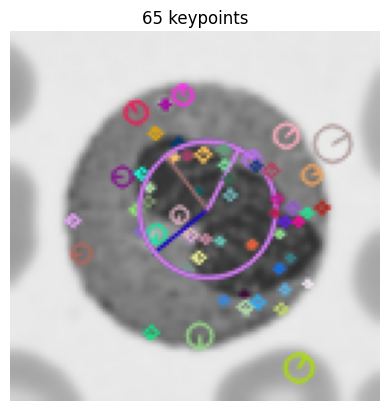

In [11]:
img = Xtr[0]
kp, _ = sift.detectAndCompute(img, None)
out = cv2.drawKeypoints(img, kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(out, cmap='gray'); plt.axis('off')
plt.title(f"{len(kp)} keypoints")
plt.show()

In [12]:
step = 128 / SIFT_GRID
pts = [((j + 0.5) * step, (i + 0.5) * step) for i in range(SIFT_GRID) for j in range(SIFT_GRID)]

def sift_feat(img):
    kps = [cv2.KeyPoint(float(x), float(y), 32, 0) for x, y in pts]
    _, des = sift.compute(img, kps)
    return des.flatten()

def sift_feats(X):
    return np.array([sift_feat(i) for i in X])

Str, Sva = sift_feats(Xtr), sift_feats(Xva)
print(Str.shape, Sva.shape)
print("SIFT feature length:", Str.shape[1])

(400, 4608) (120, 4608)
SIFT feature length: 4608


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


C=0.1  val acc=0.7167


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


C=1  val acc=0.7167
C=10  val acc=0.7167
Best C: 0.1
Accuracy: 0.7167
Macro-F1: 0.7076
[[15  8  6  1]
 [ 4 25  1  0]
 [ 6  4 17  3]
 [ 0  0  1 29]]


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


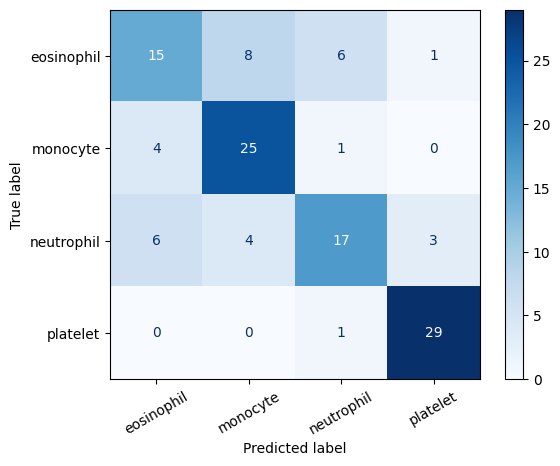

In [13]:
sift_model = fit_best(Str, ytr, Sva, yva)
report(sift_model, Sva, yva)

# **Q4. Robustness**

In [14]:
def rotate(X, deg=20):
    M = cv2.getRotationMatrix2D((64, 64), deg, 1.0)
    return np.array([cv2.warpAffine(i, M, (128, 128)) for i in X])

def add_noise(X, sigma=0.05):
    r = np.random.default_rng(SEED)
    x = X / 255.0 + r.normal(0, sigma, X.shape)
    return np.round(np.clip(x, 0, 1) * 255).astype(np.uint8)

cases = {'Clean': Xte, 'Rotated': rotate(Xte), 'Noisy': add_noise(Xte)}

rows = []
for name, model, fe in [('HOG + SVM', hog_model, hog_feats), ('SIFT + SVM', sift_model, sift_feats)]:
    row = {'Model': name}
    for case, X in cases.items():
        row[case + ' accuracy'] = round(accuracy_score(yte, model.predict(fe(X))), 4)
    rows.append(row)

table = pd.DataFrame(rows)
table

,Model,Clean accuracy,Rotated accuracy,Noisy accuracy
0,HOG + SVM,0.7250,0.6083,0.5000
1,SIFT + SVM,0.7333,0.5333,0.7333


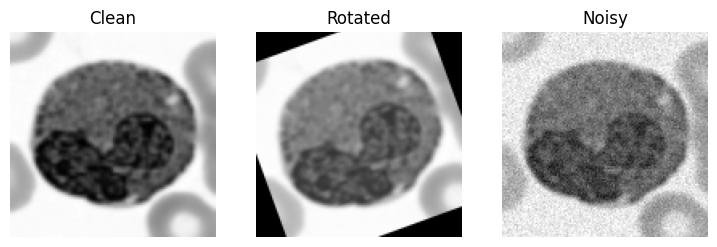

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, (k, X) in zip(ax, cases.items()):
    a.imshow(X[0], cmap='gray'); a.set_title(k); a.axis('off')
plt.show()

# **Q5. Short answers and AI log**

In [16]:
for name, model, F in [('HOG', hog_model, Hva), ('SIFT', sift_model, Sva)]:
    cm = confusion_matrix(yva, model.predict(F))
    np.fill_diagonal(cm, 0)
    i, j = np.unravel_index(cm.argmax(), cm.shape)
    print(name, "most confused:", names[i], "->", names[j], "count:", cm[i, j])

HOG most confused: neutrophil -> eosinophil count: 9
SIFT most confused: eosinophil -> monocyte count: 8
